# Social Media Engagement Analytics Using Python
Module-End Assignment: Python for Data Analysis Dataset: social_media_engagement_5000.csv

Contents

Data Import & Setup
Data Cleaning
Data Exploration (Pandas)
Data Wrangling
Statistical Analysis
Data Visualization (Matplotlib, Seaborn, Plotly)
Functions, Loops & Text Processing (rubric skills)
Final Insights
One-Page Summary

### 1. DATA IMPORT & SETUP

In [2]:
!pip install numpy pandas matplotlib seaborn plotly

In [4]:
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from IPython.display import display, Markdown

In [5]:
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

In [9]:
df = pd.read_csv("C:\\Users\\Pawna\\Downloads\\social_media_engagement_5000.csv")
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.00,Female,Brazil,496713,image,fitness,"7,011.00",354.00,"1,157.00",5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.19
1,10860,33.00,Male,Brazil,157326,reel,food,"11,750.00","2,606.00","1,807.00",5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.20
2,86820,32.00,Female,UK,109864,text,food,"4,862.00",344.00,955.00,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.14
3,64886,51.00,Other,France,848877,text,fitness,"5,350.00","1,083.00","1,049.00",229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.11
4,16265,34.00,Other,UK,449706,image,fitness,"12,682.00","2,735.00","1,300.00",4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.78
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44.00,Male,Australia,441541,video,education,"16,210.00","2,013.00","1,837.00",6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.47
4996,22100,38.00,Other,UAE,677076,reel,education,"16,924.00","2,734.00","1,583.00",7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.62
4997,67021,63.00,Female,USA,273595,text,travel,"13,487.00",NaN,167.00,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.68
4998,29800,13.00,Female,Germany,785644,video,fitness,"16,894.00","1,289.00","1,713.00",4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.22


In [10]:
print("Loaded shape:", df.shape)
df.head()

Loaded shape: (5000, 19)


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.00,Female,Brazil,496713,image,fitness,"7,011.00",354.00,"1,157.00",5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.19
1,10860,33.00,Male,Brazil,157326,reel,food,"11,750.00","2,606.00","1,807.00",5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.20
2,86820,32.00,Female,UK,109864,text,food,"4,862.00",344.00,955.00,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.14
3,64886,51.00,Other,France,848877,text,fitness,"5,350.00","1,083.00","1,049.00",229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.11
4,16265,34.00,Other,UK,449706,image,fitness,"12,682.00","2,735.00","1,300.00",4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.78


In [11]:
df.columns = (df.columns.str.strip().str.lower()
                .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))
print(list(df.columns))
df.dtypes

['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate']


user_id               int64
age                 float64
gender               object
country              object
post_id               int64
post_type            object
post_category        object
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at            object
follower_count        int64
is_verified            bool
device_type          object
sentiment            object
hashtags             object
engagement_rate     float64
dtype: object

In [13]:
def find_col(*candidates):
    for c in candidates:
        if c in df.columns:
            return c
    for c in candidates:                       # partial match fallback
        hit = [x for x in df.columns if c in x]
        if hit:
            return hit[0]
    return None

COL = {
    "date":        find_col("post_date", "date", "timestamp", "created_at", "post_time", "datetime"),
    "hour":        find_col("post_hour", "hour", "hour_of_day", "time_of_day"),
    "post_type":   find_col("post_type", "content_type", "media_type", "type"),
    "category":    find_col("category", "content_category", "topic"),
    "country":     find_col("country", "location", "region"),
    "gender":      find_col("gender", "sex"),
    "age":         find_col("age", "user_age"),
    "device":      find_col("device", "device_type", "platform"),
    "verified":    find_col("verified", "is_verified", "verified_account"),
    "followers":   find_col("followers", "follower_count"),
    "likes":       find_col("likes", "like_count"),
    "comments":    find_col("comments", "comment_count"),
    "shares":      find_col("shares", "share_count"),
    "impressions": find_col("impressions", "views", "reach"),
    "watch_time":  find_col("watch_time", "watch_time_seconds", "avg_watch_time"),
    "eng_rate":    find_col("engagement_rate", "eng_rate"),
    "sentiment":   find_col("sentiment", "sentiment_label"),
    "text":        find_col("hashtags", "caption", "post_text", "text", "content", "post_content"),
}
COL

{'date': None,
 'hour': None,
 'post_type': 'post_type',
 'category': 'post_category',
 'country': 'country',
 'gender': 'gender',
 'age': 'age',
 'device': 'device_type',
 'verified': 'is_verified',
 'followers': 'follower_count',
 'likes': 'likes',
 'comments': 'comments',
 'shares': 'shares',
 'impressions': None,
 'watch_time': 'watch_time_sec',
 'eng_rate': 'engagement_rate',
 'sentiment': 'sentiment',
 'text': 'hashtags'}

In [14]:
print("Duplicate/odd types before conversion:")
display(df.dtypes.to_frame("dtype"))

# Date columns -> datetime
if COL["date"]:
    df[COL["date"]] = pd.to_datetime(df[COL["date"]], errors="coerce")
for c in df.columns:                           # any other date-like column
    if ("date" in c or "time_stamp" in c or "timestamp" in c) and c != COL["date"] \
            and df[c].dtype == "object":
        df[c] = pd.to_datetime(df[c], errors="coerce")

# Numeric columns -> numeric (bad strings become NaN)
num_keys = ["age", "followers", "likes", "comments", "shares",
            "impressions", "watch_time", "eng_rate", "hour"]
for k in num_keys:
    if COL[k]:
        df[COL[k]] = pd.to_numeric(df[COL[k]], errors="coerce")

df.dtypes

Duplicate/odd types before conversion:


,dtype
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


user_id               int64
age                 float64
gender               object
country              object
post_id               int64
post_type            object
post_category        object
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at            object
follower_count        int64
is_verified            bool
device_type          object
sentiment            object
hashtags             object
engagement_rate     float64
dtype: object

In [15]:
likes_arr = df[COL["likes"]].to_numpy(dtype=float)
valid = likes_arr[~np.isnan(likes_arr)]

print("Array shape         :", likes_arr.shape)
print("Mean / median       :", np.mean(valid).round(2), "/", np.median(valid).round(2))
print("Min / max           :", valid.min(), "/", valid.max())
print("Std deviation       :", np.std(valid).round(2))
print("25/50/75 percentile :", np.percentile(valid, [25, 50, 75]))
print("Likes above mean    :", int((valid > valid.mean()).sum()))


eng_matrix = df[[COL["likes"], COL["comments"], COL["shares"]]].to_numpy(dtype=float)
print("\nMatrix shape:", eng_matrix.shape)
print("Column means (likes, comments, shares):", np.nanmean(eng_matrix, axis=0).round(2))
print("Total interactions (first 5 rows)     :", np.nansum(eng_matrix, axis=1)[:5])

Array shape         : (5000,)
Mean / median       : 10107.04 / 10105.5
Min / max           : 10.0 / 19998.0
Std deviation       : 5789.22
25/50/75 percentile : [ 5068.5 10105.5 15115. ]
Likes above mean    : 2424

Matrix shape: (5000, 3)
Column means (likes, comments, shares): [10107.04  1502.2   1002.63]
Total interactions (first 5 rows)     : [ 8522. 16163.  6161.  7482. 16717.]


### 2. DATA CLEANING

In [16]:
missing = pd.DataFrame({"missing": df.isnull().sum(),
                        "percent": (df.isna().mean() * 100).round(2)})
missing[missing.missing > 0].sort_values("missing", ascending=False)

,missing,percent
age,150,3.00
gender,150,3.00
likes,150,3.00
comments,150,3.00
shares,150,3.00
sentiment,150,3.00


In [21]:
rows_before = len(df)


for k in ["age", "followers", "likes", "comments", "shares",
          "impressions", "watch_time", "eng_rate"]:
    c = COL[k]
    if c:
        df[c] = df[c].fillna(df[c].median())


for k in ["post_type", "category", "country", "gender", "device", "sentiment"]:
    c = COL[k]
    if c:
        df[c] = df[c].fillna(df[c].mode()[0])


if COL["date"]:
    df = df.sort_values(COL["date"]).reset_index(drop=True)
    df[COL["date"]] = df[COL["date"]].ffill().bfill()
if COL["hour"]:
    df[COL["hour"]] = df[COL["hour"]].ffill().bfill()


df = df.dropna(subset=[COL["date"]]) if COL["date"] else df
print("Rows before / after:", rows_before, "/", len(df))
print("Missing values left:", int(df.isnull().sum().sum()))

Rows before / after: 5000 / 5000
Missing values left: 0


In [22]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 0
Shape after removing duplicates: (5000, 19)


### 3. DATA FORMATTING 

In [23]:
for k in ["post_type", "category", "country", "gender", "device", "sentiment"]:
    c = COL[k]
    if c:
        df[c] = (df[c].astype(str).str.strip().str.replace(r"\s+", " ", regex=True).str.title())
        if k == "country":                     # keep codes such as USA / UK upper-case
            df[c] = df[c].apply(lambda x: x.upper() if len(x) <= 3 else x)


gender_map = {"M": "Male", "Male": "Male", "Man": "Male",
              "F": "Female", "Female": "Female", "Woman": "Female",
              "Other": "Other", "Non-Binary": "Other", "Nb": "Other", "Unknown": "Other"}
if COL["gender"]:
    df[COL["gender"]] = df[COL["gender"]].map(gender_map).fillna("Other")
    print(df[COL["gender"]].value_counts())

gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64


In [24]:
if COL["verified"]:
    v = df[COL["verified"]].astype(str).str.strip().str.lower()
    df[COL["verified"]] = v.isin(["true", "1", "yes", "y", "verified"])
    print(df[COL["verified"]].value_counts())

is_verified
False    4517
True      483
Name: count, dtype: int64


In [25]:
report = []
for k in ["likes", "comments", "shares", "impressions", "followers", "watch_time"]:
    c = COL[k]
    if not c:
        continue
    neg = int((df[c] < 0).sum())
    df.loc[df[c] < 0, c] = np.nan
    df[c] = df[c].fillna(df[c].median())
    cap = df[c].quantile(0.995)
    capped = int((df[c] > cap).sum())
    df[c] = df[c].clip(upper=cap)
    report.append((c, neg, capped, round(cap, 2)))

if COL["age"]:
    bad_age = int(((df[COL["age"]] < 13) | (df[COL["age"]] > 100)).sum())
    df.loc[(df[COL["age"]] < 13) | (df[COL["age"]] > 100), COL["age"]] = np.nan
    df[COL["age"]] = df[COL["age"]].fillna(df[COL["age"]].median())
    report.append((COL["age"], bad_age, 0, "13-100"))


pd.DataFrame(report, columns=["column", "negative/invalid fixed", "outliers capped", "cap value"])

,column,negative/invalid fixed,outliers capped,cap value
0,likes,0,25,"19,918.01"
1,comments,0,25,"2,988.00"
2,shares,0,24,"1,989.00"
3,follower_count,0,25,"795,956.39"
4,watch_time_sec,0,25,"7,959.00"
5,age,0,0,13-100


In [26]:
text_col = COL["text"]
if text_col and df[text_col].dtype == "object":
    df["hashtag_count"] = df[text_col].fillna("").astype(str).str.count(r"#\w+")
    
    if df["hashtag_count"].sum() == 0:
        df["hashtag_count"] = (df[text_col].fillna("").astype(str)
                                 .apply(lambda s: len([t for t in re.split(r"[,\s]+", s) if t])))
else:
    df["hashtag_count"] = 0
print(df["hashtag_count"].value_counts().sort_index())

hashtag_count
1    1655
2    1697
3    1648
Name: count, dtype: int64


In [27]:
sent_map = {"Pos": "Positive", "Positive": "Positive", "Good": "Positive",
            "Neg": "Negative", "Negative": "Negative", "Bad": "Negative",
            "Neu": "Neutral", "Neutral": "Neutral"}
if COL["sentiment"]:
    df[COL["sentiment"]] = df[COL["sentiment"]].map(sent_map).fillna("Neutral")
    print(df[COL["sentiment"]].value_counts())

sentiment
Positive    2513
Neutral     1527
Negative     960
Name: count, dtype: int64


In [28]:
if not COL["eng_rate"]:
    df["engagement_rate"] = ((df[COL["likes"]] + df[COL["comments"]] + df[COL["shares"]])
                             / df[COL["impressions"]].replace(0, np.nan) * 100).fillna(0)
    COL["eng_rate"] = "engagement_rate"


if not COL["hour"] and COL["date"] and df[COL["date"]].dt.hour.nunique() > 1:
    df["hour"] = df[COL["date"]].dt.hour
    COL["hour"] = "hour"

print("Clean shape:", df.shape, "| missing:", int(df.isnull().sum().sum()))
df.head()

Clean shape: (5000, 20) | missing: 0


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.00,Female,Brazil,496713,Image,Fitness,"7,011.00",354.00,"1,157.00","5,726.00",44650,17-12-2022,"81,734.00",False,Mobile,Negative,#foodie #travel #love,0.19,3
1,10860,33.00,Male,Brazil,157326,Reel,Food,"11,750.00","2,606.00","1,807.00","5,947.00",80216,02-06-2023,"5,963.00",False,Mobile,Negative,#fitness,0.20,1
2,86820,32.00,Female,UK,109864,Text,Food,"4,862.00",344.00,955.00,"6,946.00",44858,07-05-2023,"501,783.00",False,Tablet,Positive,#foodie,0.14,1
3,64886,51.00,Other,France,848877,Text,Fitness,"5,350.00","1,083.00","1,049.00",229.00,70455,12-02-2023,"480,212.00",False,Mobile,Negative,#music #foodie #fun,0.11,3
4,16265,34.00,Other,UK,449706,Image,Fitness,"12,682.00","2,735.00","1,300.00","4,798.00",6019,23-05-2023,"383,936.00",False,Mobile,Negative,#travel,2.78,1


### 3. DATA EXPLORATION USING PANDAS

In [29]:
print("Shape:", df.shape)
print("Columns:", list(df.columns))
display(df.head())
display(df.tail())

Shape: (5000, 20)
Columns: ['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'hashtag_count']


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.00,Female,Brazil,496713,Image,Fitness,"7,011.00",354.00,"1,157.00","5,726.00",44650,17-12-2022,"81,734.00",False,Mobile,Negative,#foodie #travel #love,0.19,3
1,10860,33.00,Male,Brazil,157326,Reel,Food,"11,750.00","2,606.00","1,807.00","5,947.00",80216,02-06-2023,"5,963.00",False,Mobile,Negative,#fitness,0.20,1
2,86820,32.00,Female,UK,109864,Text,Food,"4,862.00",344.00,955.00,"6,946.00",44858,07-05-2023,"501,783.00",False,Tablet,Positive,#foodie,0.14,1
3,64886,51.00,Other,France,848877,Text,Fitness,"5,350.00","1,083.00","1,049.00",229.00,70455,12-02-2023,"480,212.00",False,Mobile,Negative,#music #foodie #fun,0.11,3
4,16265,34.00,Other,UK,449706,Image,Fitness,"12,682.00","2,735.00","1,300.00","4,798.00",6019,23-05-2023,"383,936.00",False,Mobile,Negative,#travel,2.78,1


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44.00,Male,Australia,441541,Video,Education,"16,210.00","2,013.00","1,837.00","6,190.00",42977,25-06-2022,"646,147.00",False,Mobile,Positive,#travel #fun,0.47,2
4996,22100,38.00,Other,UAE,677076,Reel,Education,"16,924.00","2,734.00","1,583.00","7,764.00",34196,18-11-2022,"584,603.00",False,Desktop,Negative,#foodie #reels,0.62,2
4997,67021,63.00,Female,USA,273595,Text,Travel,"13,487.00","1,497.00",167.00,"7,466.00",23680,06-04-2023,"483,550.00",False,Desktop,Positive,#lifestyle #tech,0.68,2
4998,29800,13.00,Female,Germany,785644,Video,Fitness,"16,894.00","1,289.00","1,713.00","4,991.00",89013,16-05-2022,"183,295.00",False,Tablet,Positive,#reels #love #fitness,0.22,3
4999,73400,54.00,Other,Japan,712252,Text,Travel,"14,830.00",503.00,"1,798.00","3,743.00",14234,04-03-2023,"585,760.00",False,Desktop,Neutral,#foodie #lifestyle #fashion,1.20,3


In [30]:
df.info()
print()
df.dtypes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               5000 non-null   float64
 2   gender            5000 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             5000 non-null   float64
 8   comments          5000 non-null   float64
 9   shares            5000 non-null   float64
 10  watch_time_sec    5000 non-null   float64
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   float64
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment         5000 non-null   object 


user_id               int64
age                 float64
gender               object
country              object
post_id               int64
post_type            object
post_category        object
likes               float64
comments            float64
shares              float64
watch_time_sec      float64
impression_count      int64
posted_at            object
follower_count      float64
is_verified            bool
device_type          object
sentiment            object
hashtags             object
engagement_rate     float64
hashtag_count         int64
dtype: object

In [31]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
user_id,"5,000.00","54,561.89","26,090.37","10,055.00","32,309.50","54,374.50","77,180.50","99,963.00"
age,"5,000.00",38.44,14.69,13.00,26.00,38.00,51.00,64.00
post_id,"5,000.00","548,042.91","260,646.96","100,068.00","322,543.50","548,077.50","771,574.50","999,455.00"
likes,"5,000.00","10,106.74","5,701.85",10.00,"5,235.00","10,105.50","14,959.00","19,918.01"
comments,"5,000.00","1,502.01",856.34,0.00,792.00,"1,497.00","2,235.25","2,988.01"
shares,"5,000.00","1,002.88",570.81,0.00,511.00,"1,012.00","1,483.00","1,989.00"
watch_time_sec,"5,000.00","4,014.40","2,307.92",0.00,"2,017.75","4,034.50","6,020.25","7,959.01"
impression_count,"5,000.00","50,013.73","28,844.94",105.00,"24,988.25","49,934.50","74,662.25","99,995.00"
follower_count,"5,000.00","393,689.11","230,911.95",87.00,"194,480.00","388,982.00","589,744.25","795,956.39"
engagement_rate,"5,000.00",0.96,5.32,0.01,0.15,0.25,0.50,191.50


In [32]:
cat_cols = [COL[k] for k in ["post_type", "category", "country", "gender", "device", "sentiment"] if COL[k]]
for c in cat_cols:
    print(f"--- {c}  (nunique = {df[c].nunique()}) ---")
    print("unique:", df[c].unique())
    display(df[c].value_counts().to_frame("count"))

--- post_type  (nunique = 4) ---
unique: ['Image' 'Reel' 'Text' 'Video']


,count
post_type,
Reel,1283
Image,1247
Text,1245
Video,1225


--- post_category  (nunique = 8) ---
unique: ['Fitness' 'Food' 'Tech' 'Travel' 'Fashion' 'Lifestyle' 'Education'
 'Music']


,count
post_category,
Fitness,675
Tech,665
Music,635
Education,631
Lifestyle,607
Travel,600
Fashion,594
Food,593


--- country  (nunique = 10) ---
unique: ['Brazil' 'UK' 'France' 'Canada' 'Japan' 'Australia' 'India' 'UAE'
 'Germany' 'USA']


...

,count
gender,
Male,1849
Other,1581
Female,1570


--- device_type  (nunique = 3) ---
unique: ['Mobile' 'Tablet' 'Desktop']


,count
device_type,
Mobile,1684
Tablet,1658
Desktop,1658


--- sentiment  (nunique = 3) ---
unique: ['Negative' 'Positive' 'Neutral']


,count
sentiment,
Positive,2513
Neutral,1527
Negative,960


In [42]:
num_cols = [COL[k] for k in ["age", "followers", "likes", "comments", "shares",
                              "impressions", "watch_time", "eng_rate"] if COL[k]]
corr = df[num_cols].corr()
corr

,age,follower_count,likes,comments,shares,watch_time_sec,engagement_rate
age,1.00,-0.02,-0.04,-0.01,0.01,0.01,0.01
follower_count,-0.02,1.00,-0.02,-0.01,-0.01,0.00,0.00
likes,-0.04,-0.02,1.00,-0.02,0.00,0.01,0.09
comments,-0.01,-0.01,-0.02,1.00,0.01,-0.02,0.00
shares,0.01,-0.01,0.00,0.01,1.00,0.01,0.02
watch_time_sec,0.01,0.00,0.01,-0.02,0.01,1.00,-0.00
engagement_rate,0.01,0.00,0.09,0.00,0.02,-0.00,1.00


In [44]:
print(COL["country"], COL["impressions"])
print(list(df.columns))

country None
['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'hashtag_count']


In [45]:
COL["country"] = "country"        
COL["impressions"] = "impression_count"

In [47]:
display(df.groupby(COL["post_type"])[COL["likes"]].mean().sort_values(ascending=False).to_frame("avg_likes"))
display(df.groupby(COL["country"])[COL["impressions"]].mean().sort_values(ascending=False).to_frame("avg_impressions"))
display(df.groupby(COL["category"])[[COL["likes"], COL["comments"], COL["shares"]]].mean())

,avg_likes
post_type,
Video,"10,188.29"
Image,"10,104.66"
Text,"10,099.80"
Reel,"10,037.63"


,avg_impressions
country,
India,"52,462.39"
France,"51,727.67"
USA,"51,263.87"
UK,"51,119.39"
Japan,"49,616.14"
Brazil,"49,193.17"
UAE,"48,928.41"
Canada,"48,703.15"
Germany,"48,605.41"


,likes,comments,shares
post_category,,,
Education,"10,126.19","1,455.31",996.41
Fashion,"9,842.93","1,530.48",982.50
Fitness,"9,914.60","1,501.12","1,042.02"
Food,"10,225.32","1,510.85","1,002.76"
Lifestyle,"10,180.33","1,467.83",991.12
Music,"10,205.28","1,558.69","1,024.07"
Tech,"10,171.43","1,505.51","1,009.35"
Travel,"10,195.98","1,485.89",968.28


### 4. DATA WRANGLING

In [48]:
df["engagement_score"] = (df[COL["likes"]] * 1 + df[COL["comments"]] * 2 + df[COL["shares"]] * 3)
df["total_interactions"] = df[COL["likes"]] + df[COL["comments"]] + df[COL["shares"]]
df["log_likes"] = np.log1p(df[COL["likes"]])
df["log_impressions"] = np.log1p(df[COL["impressions"]])
df["log_followers"] = np.log1p(df[COL["followers"]])


if COL["age"]:
    df["age_group"] = pd.cut(df[COL["age"]], bins=[12, 17, 24, 34, 44, 54, 100],
                             labels=["13-17", "18-24", "25-34", "35-44", "45-54", "55+"])

if COL["date"]:
    df["month"] = df[COL["date"]].dt.month_name()
    df["day_of_week"] = df[COL["date"]].dt.day_name()

if COL["hour"]:
    df["time_of_day"] = pd.cut(df[COL["hour"]], bins=[-1, 5, 11, 17, 23],
                               labels=["Night (0-5)", "Morning (6-11)", "Afternoon (12-17)", "Evening (18-23)"])
df[["engagement_score", "total_interactions", "log_likes", "hashtag_count"]].head()

,engagement_score,total_interactions,log_likes,hashtag_count
0,"11,190.00","8,522.00",8.86,3
1,"22,383.00","16,163.00",9.37,1
2,"8,415.00","6,161.00",8.49,1
3,"10,663.00","7,482.00",8.59,3
4,"22,052.00","16,717.00",9.45,1


In [49]:
type_summary = (df.groupby(COL["post_type"])
                  .agg(type_avg_likes=(COL["likes"], "mean"),
                       type_avg_eng=(COL["eng_rate"], "mean"))
                  .reset_index())
df = df.merge(type_summary, on=COL["post_type"], how="left")
df["likes_vs_type_avg"] = df[COL["likes"]] - df["type_avg_likes"]


by_type = df.groupby(COL["post_type"])[COL["eng_rate"]].mean().rename("avg_eng_rate").reset_index()
by_type.columns = ["group", "avg_eng_rate"]; by_type.insert(0, "dimension", "post_type")
by_cat = df.groupby(COL["category"])[COL["eng_rate"]].mean().rename("avg_eng_rate").reset_index()
by_cat.columns = ["group", "avg_eng_rate"]; by_cat.insert(0, "dimension", "category")
combined = pd.concat([by_type, by_cat], ignore_index=True)
combined.sort_values("avg_eng_rate", ascending=False)

,dimension,group,avg_eng_rate
7,category,Food,1.36
10,category,Tech,1.16
3,post_type,Video,1.12
8,category,Lifestyle,1.09
2,post_type,Text,1.06
0,post_type,Image,0.90
9,category,Music,0.89
6,category,Fitness,0.87
4,category,Education,0.84
5,category,Fashion,0.81


In [50]:
metrics = {COL["likes"]: "mean", COL["comments"]: "mean", COL["shares"]: "mean",
           COL["impressions"]: "mean", COL["eng_rate"]: "mean", "engagement_score": "mean"}

for key in ["post_type", "country", "sentiment"]:
    print(f"\n===== Summary by {key} =====")
    display(df.groupby(COL[key]).agg(metrics).sort_values(COL["eng_rate"], ascending=False)
              .assign(posts=df.groupby(COL[key]).size()))


===== Summary by post_type =====


,likes,comments,shares,impression_count,engagement_rate,engagement_score,posts
post_type,,,,,,,
Video,"10,188.29","1,479.14",996.82,"49,862.01",1.12,"16,137.01",1225
Text,"10,099.80","1,499.08","1,013.95","49,987.22",1.06,"16,139.81",1245
Image,"10,104.66","1,525.19","1,019.27","49,727.42",0.90,"16,212.84",1247
Reel,"10,037.63","1,504.15",982.01,"50,462.60",0.78,"15,991.97",1283



===== Summary by country =====


,likes,comments,shares,impression_count,engagement_rate,engagement_score,posts
country,,,,,,,
Brazil,"9,886.43","1,490.43","1,008.86","49,193.17",1.54,"15,893.87",504
Australia,"10,294.02","1,485.75","1,029.67","48,346.38",1.32,"16,354.53",493
France,"10,372.44","1,478.60","1,051.76","51,727.67",1.15,"16,484.93",496
UAE,"10,227.33","1,541.20",989.04,"48,928.41",1.11,"16,276.86",503
Canada,"10,062.83","1,546.57",996.23,"48,703.15",0.92,"16,144.66",513
UK,"9,935.42","1,463.04",985.68,"51,119.39",0.85,"15,818.54",493
Japan,"10,088.62","1,530.40",959.34,"49,616.14",0.77,"16,027.45",472
Germany,"10,130.46","1,531.79",973.35,"48,605.41",0.76,"16,114.09",490
India,"9,962.22","1,494.86","1,035.24","52,462.39",0.66,"16,057.66",535



===== Summary by sentiment =====


,likes,comments,shares,impression_count,engagement_rate,engagement_score,posts
sentiment,,,,,,,
Negative,"10,207.88","1,516.07","1,007.29","50,191.96",1.04,"16,261.87",960
Neutral,"9,923.01","1,528.37",996.54,"49,515.97",0.99,"15,969.35",1527
Positive,"10,179.74","1,480.62","1,005.06","50,248.11",0.92,"16,156.16",2513


### 5. STATISTICAL ANALYSIS

In [51]:
stat_cols = [COL[k] for k in ["likes", "comments", "shares", "watch_time", "eng_rate", "followers"] if COL[k]]
rows = {}
for c in stat_cols:
    s = df[c]
    rows[c] = {
        "mean": s.mean(), "median": s.median(), "mode": s.mode().iloc[0],
        "std": s.std(), "variance": s.var(),
        "min": s.min(), "p25": s.quantile(.25), "p50": s.quantile(.50),
        "p75": s.quantile(.75), "p90": s.quantile(.90), "p95": s.quantile(.95),
        "max": s.max(),
        "skewness": s.skew(), "kurtosis": s.kurt(),
    }
stats_table = pd.DataFrame(rows).T
stats_table

,mean,median,mode,std,variance,min,p25,p50,p75,p90,p95,max,skewness,kurtosis
likes,"10,106.74","10,105.50","10,105.50","5,701.85","32,511,043.64",10.00,"5,235.00","10,105.50","14,959.00","18,016.30","19,097.05","19,918.01",-0.01,-1.15
comments,"1,502.01","1,497.00","1,497.00",856.34,"733,313.61",0.00,792.00,"1,497.00","2,235.25","2,695.10","2,861.00","2,988.01",0.00,-1.14
shares,"1,002.88","1,012.00","1,012.00",570.81,"325,821.41",0.00,511.00,"1,012.00","1,483.00","1,795.10","1,901.05","1,989.00",-0.01,-1.15
watch_time_sec,"4,014.40","4,034.50","7,959.01","2,307.92","5,326,503.39",0.00,"2,017.75","4,034.50","6,020.25","7,212.10","7,577.05","7,959.01",-0.02,-1.20
engagement_rate,0.96,0.25,0.01,5.32,28.28,0.01,0.15,0.25,0.50,1.20,2.33,191.50,18.78,482.99
follower_count,"393,689.11","388,982.00","795,956.39","230,911.95","53,320,330,951.96",87.00,"194,480.00","388,982.00","589,744.25","717,755.90","760,174.35","795,956.39",0.04,-1.19


In [52]:
for c, r in stats_table.iterrows():
    shape = "right-skewed (a few viral posts)" if r["skewness"] > 0.5 else \
            "left-skewed" if r["skewness"] < -0.5 else "roughly symmetric"
    print(f"{c:<16} mean {r['mean']:>12,.2f} | median {r['median']:>12,.2f} | {shape}")

likes            mean    10,106.74 | median    10,105.50 | roughly symmetric
comments         mean     1,502.01 | median     1,497.00 | roughly symmetric
shares           mean     1,002.88 | median     1,012.00 | roughly symmetric
watch_time_sec   mean     4,014.40 | median     4,034.50 | roughly symmetric
engagement_rate  mean         0.96 | median         0.25 | right-skewed (a few viral posts)
follower_count   mean   393,689.11 | median   388,982.00 | roughly symmetric


### 6. DATA VISUALIZATION

#### Matplotlib

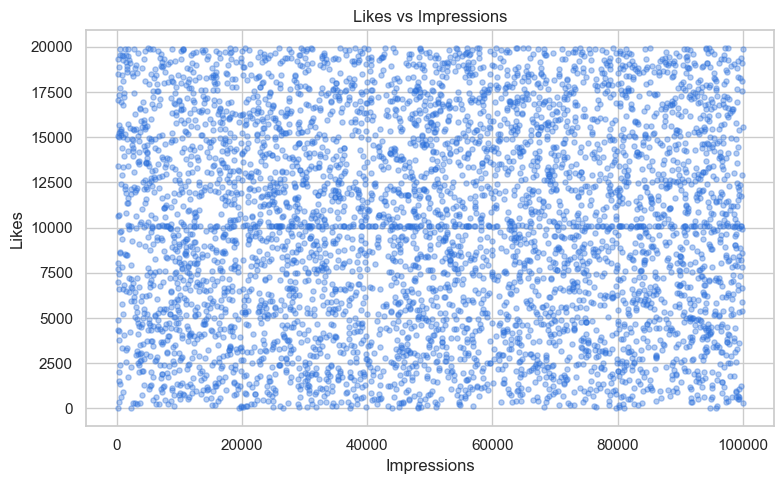

In [53]:
#scatterplot- likes vs impression
plt.figure(figsize=(8, 5))
plt.scatter(df[COL["impressions"]], df[COL["likes"]], alpha=0.35, s=14, color="#2a6fdb")
plt.title("Likes vs Impressions"); plt.xlabel("Impressions"); plt.ylabel("Likes")
plt.tight_layout(); plt.show()

In [59]:
print(list(df.columns))

['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'hashtag_count', 'engagement_score', 'total_interactions', 'log_likes', 'log_impressions', 'log_followers', 'age_group', 'type_avg_likes', 'type_avg_eng', 'likes_vs_type_avg']


In [61]:
COL["date"] = "posted_at"      # exact name from the list above
df[COL["date"]] = pd.to_datetime(df[COL["date"]], errors="coerce")

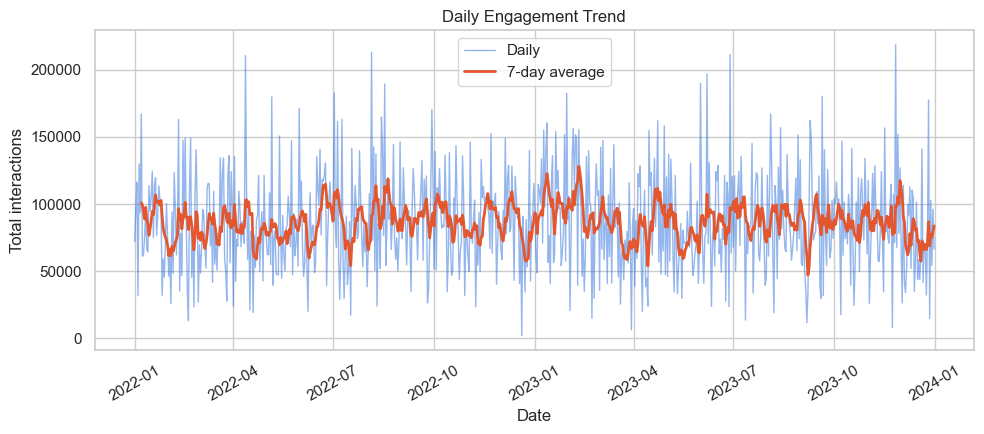

In [63]:
#Linechart - daily engagement trend
daily = df.groupby(df[COL["date"]].dt.date)["total_interactions"].sum()
plt.figure(figsize=(10, 4.5))
plt.plot(daily.index, daily.values, color="#2a6fdb", linewidth=1, alpha=.5, label="Daily")
plt.plot(daily.index, daily.rolling(7).mean(), color="#e4572e", linewidth=2, label="7-day average")
plt.title("Daily Engagement Trend"); plt.xlabel("Date"); plt.ylabel("Total interactions")
plt.legend(); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

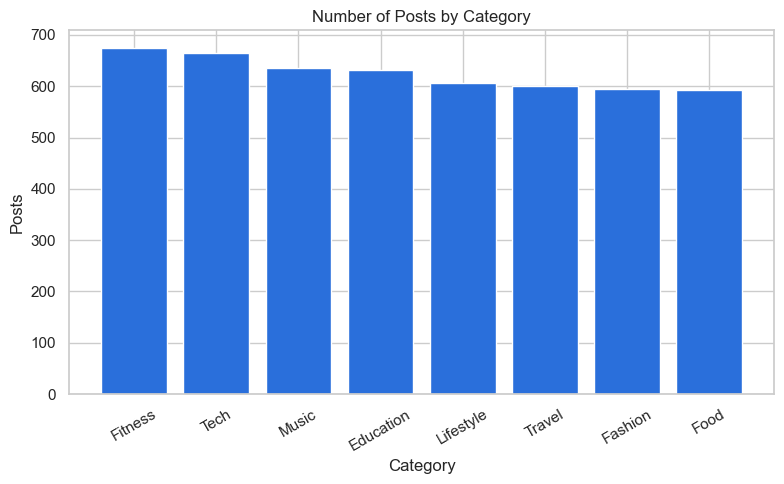

In [55]:
#Barchart - posts by category
counts = df[COL["category"]].value_counts()
plt.figure(figsize=(8, 5))
plt.bar(counts.index, counts.values, color="#2a6fdb")
plt.title("Number of Posts by Category"); plt.xlabel("Category"); plt.ylabel("Posts")
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

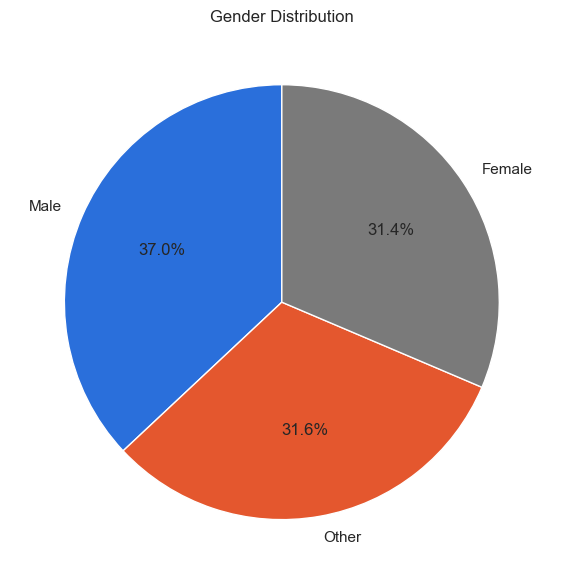

In [56]:
#Piechart - gender distribution
g = df[COL["gender"]].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(g.values, labels=g.index, autopct="%1.1f%%", startangle=90,
        colors=["#2a6fdb", "#e4572e", "#7a7a7a"][:len(g)])
plt.title("Gender Distribution"); plt.tight_layout(); plt.show()

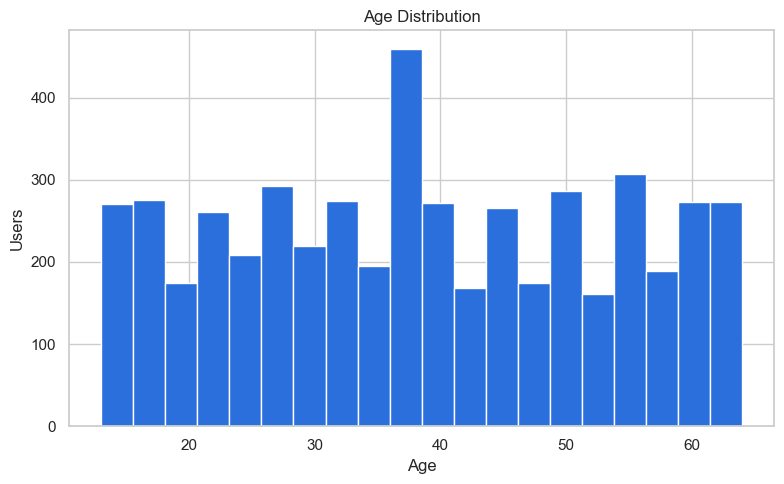

In [57]:
#Histogram - age
plt.figure(figsize=(8, 5))
plt.hist(df[COL["age"]], bins=20, color="#2a6fdb", edgecolor="white")
plt.title("Age Distribution"); plt.xlabel("Age"); plt.ylabel("Users")
plt.tight_layout(); plt.show()

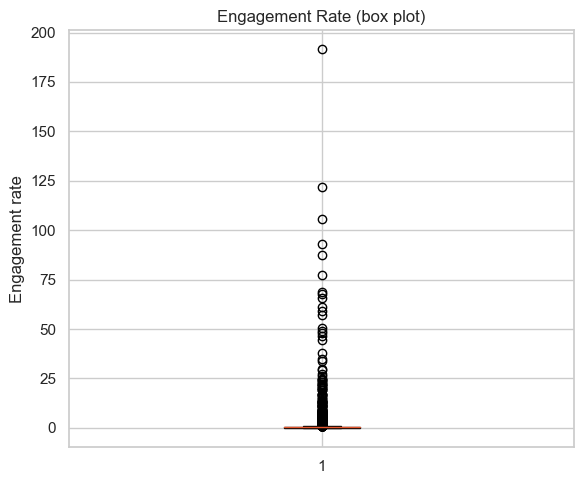

In [58]:
#Boxchart - engagement rate
plt.figure(figsize=(6, 5))
plt.boxplot(df[COL["eng_rate"]], vert=True, patch_artist=True,
            boxprops=dict(facecolor="#bcd4f6"), medianprops=dict(color="#e4572e"))
plt.title("Engagement Rate (box plot)"); plt.ylabel("Engagement rate")
plt.tight_layout(); plt.show()

#### Seaborn

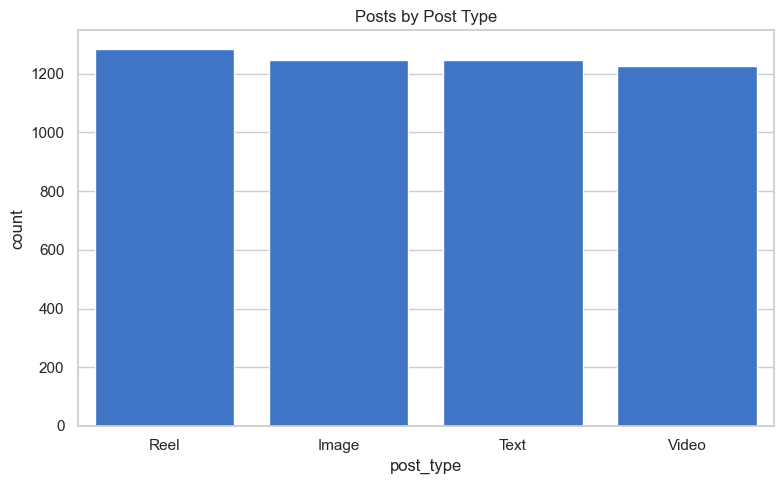

In [64]:
#Countplot - post type
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x=COL["post_type"], order=df[COL["post_type"]].value_counts().index, color="#2a6fdb")
plt.title("Posts by Post Type"); plt.tight_layout(); plt.show()

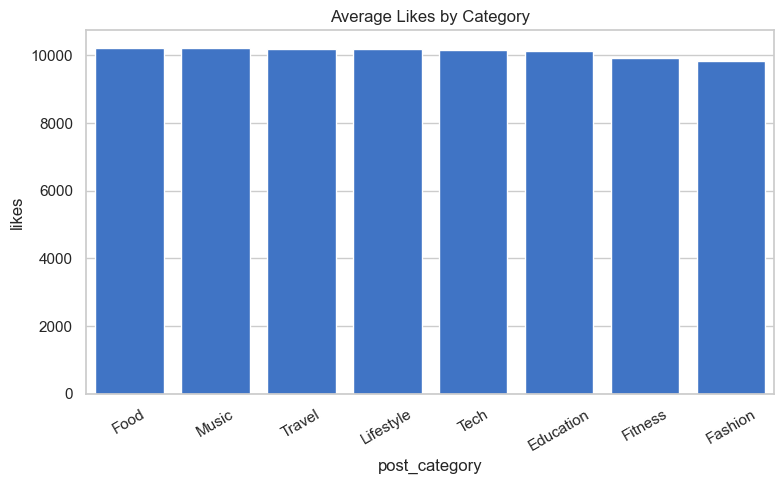

In [65]:
#Barplot - average likes by category
plt.figure(figsize=(8, 5))
order = df.groupby(COL["category"])[COL["likes"]].mean().sort_values(ascending=False).index
sns.barplot(data=df, x=COL["category"], y=COL["likes"], order=order, color="#2a6fdb", errorbar=None)
plt.title("Average Likes by Category"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

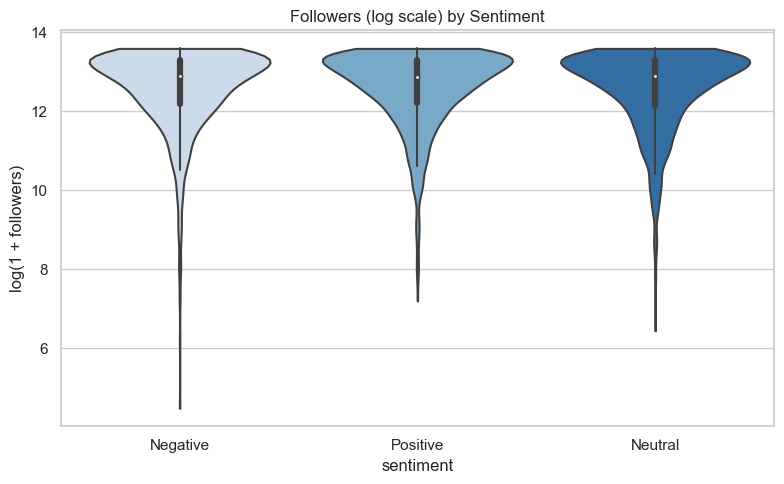

In [70]:
#Violin - followers vs sentiment
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x=COL["sentiment"], y="log_followers", palette="Blues", cut=0)
plt.title("Followers (log scale) by Sentiment"); plt.ylabel("log(1 + followers)")
plt.tight_layout(); plt.show()

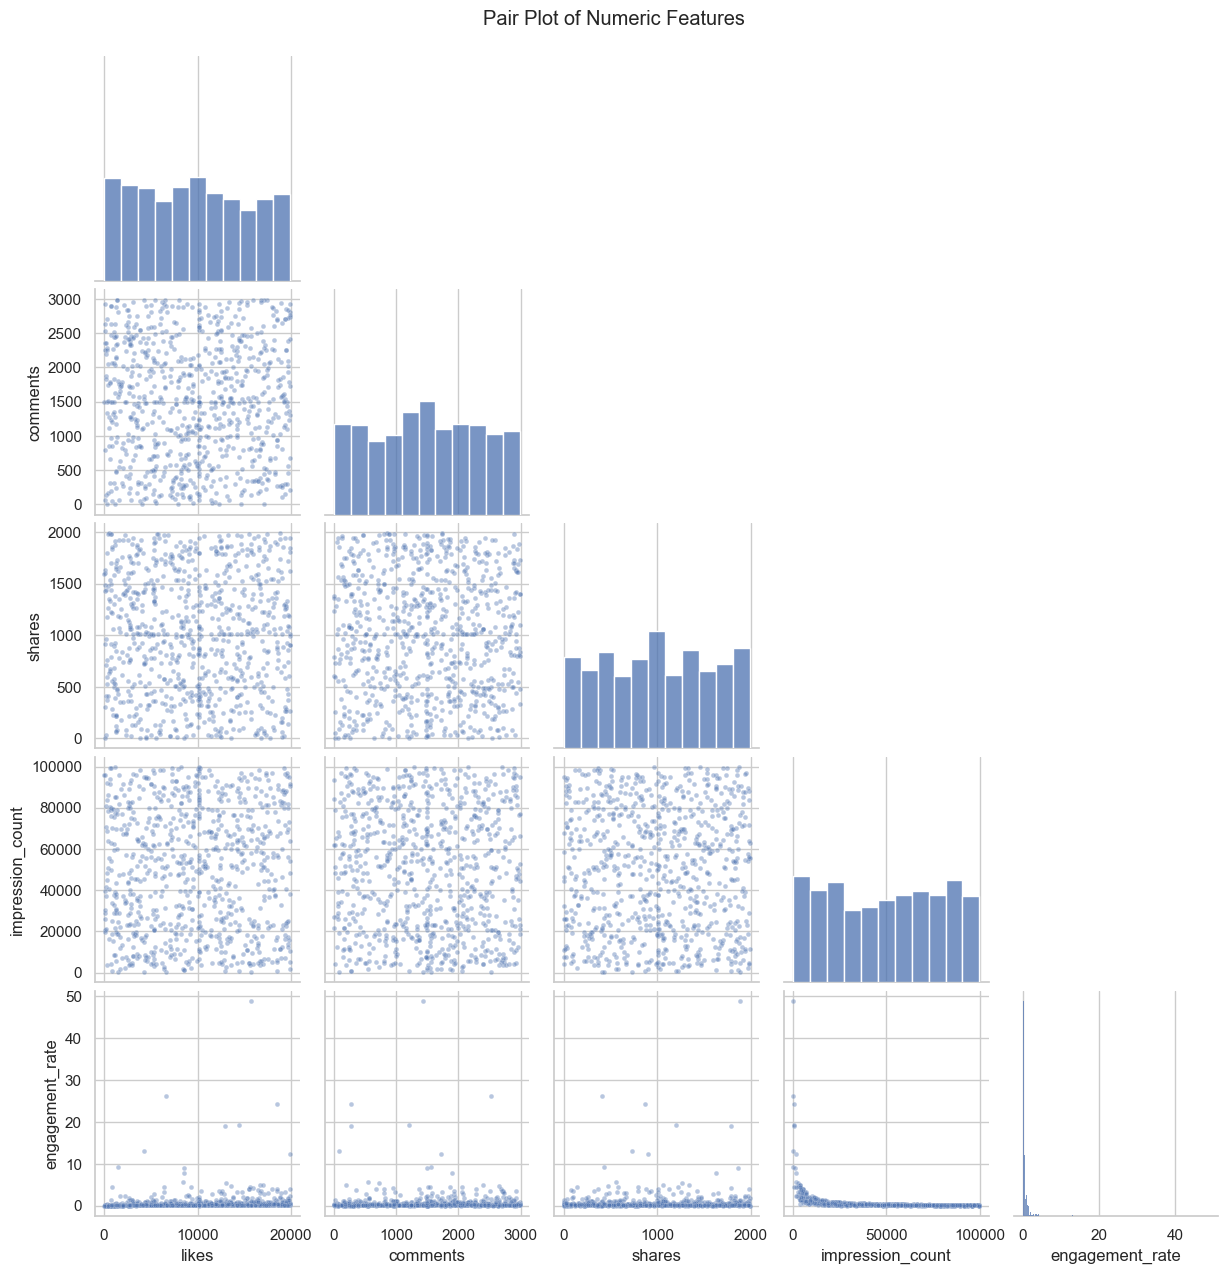

In [67]:
#Pairplot - numeric features (sampled for speed)
pair_cols = [COL[k] for k in ["likes", "comments", "shares", "impressions", "eng_rate"] if COL[k]]
sns.pairplot(df[pair_cols].sample(min(800, len(df)), random_state=1),
             corner=True, plot_kws=dict(alpha=.4, s=12))
plt.suptitle("Pair Plot of Numeric Features", y=1.02); plt.show()

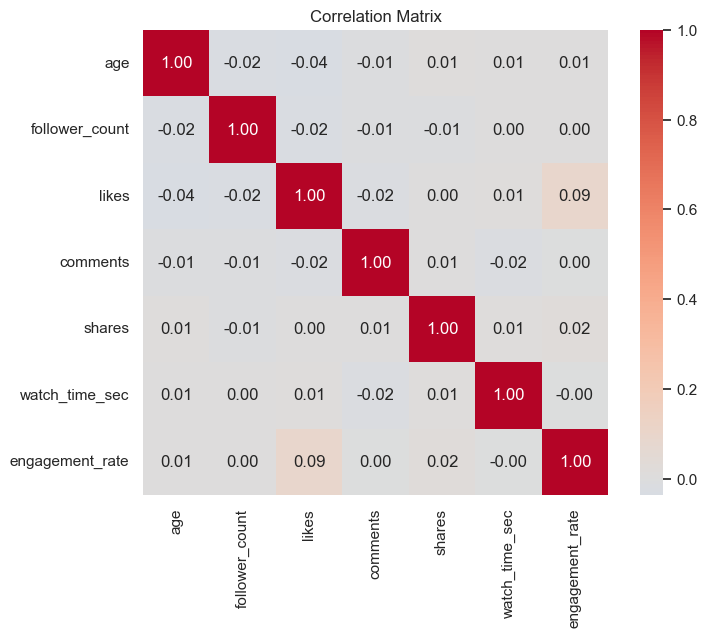

In [68]:
#Heatmap - correlation matrix
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Matrix"); plt.tight_layout(); plt.show()

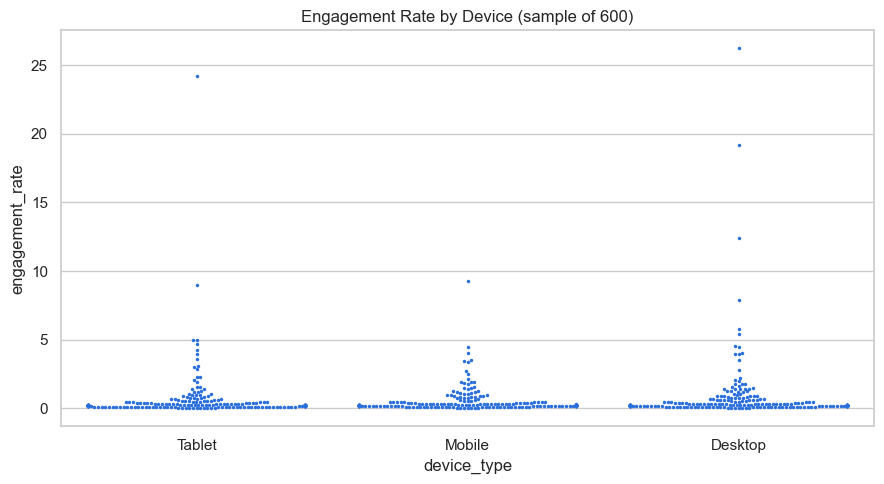

In [69]:
#Swarmplot - engagement vs device 
sample = df.sample(min(600, len(df)), random_state=1)
plt.figure(figsize=(9, 5))
sns.swarmplot(data=sample, x=COL["device"], y=COL["eng_rate"], size=2.5, color="#2a6fdb")
plt.title("Engagement Rate by Device (sample of 600)"); plt.tight_layout(); plt.show()

#### Plotly(interactive)

In [71]:
#Interactive line chart- monthly engagement
monthly = (df.set_index(COL["date"]).resample("MS")["total_interactions"].sum().reset_index())
fig = px.line(monthly, x=COL["date"], y="total_interactions", markers=True,
              title="Monthly Total Engagement")
fig.show()

In [72]:
#Interactive bar chart - average engagement rate by country
c = df.groupby(COL["country"])[COL["eng_rate"]].mean().sort_values(ascending=False).reset_index()
fig = px.bar(c, x=COL["country"], y=COL["eng_rate"], color=COL["eng_rate"],
             color_continuous_scale="Blues", title="Average Engagement Rate by Country")
fig.show()

In [73]:
#Interactive bubble chart - followers vs likes, sized by impressions
fig = px.scatter(df.sample(min(1000, len(df)), random_state=1),
                 x=COL["followers"], y=COL["likes"], size=COL["impressions"],
                 color=COL["post_type"], opacity=.6, log_x=True, size_max=30,
                 hover_data=[COL["country"], COL["category"]],
                 title="Followers vs Likes (bubble size = impressions)")
fig.show()

In [74]:
#Interactive scatter - impressions vs likes coloured by sentiment
fig = px.scatter(df.sample(min(1500, len(df)), random_state=2),
                 x=COL["impressions"], y=COL["likes"], color=COL["sentiment"],
                 opacity=.6, title="Impressions vs Likes by Sentiment")
fig.show()

### FUNCTIONS, LOOPS , TEXT PROCESSING

In [75]:
def clean_text(s):
    """Lower-case, strip punctuation (keeping # for hashtags), normalise spaces."""
    s = str(s).lower()
    s = re.sub(r"[^\w\s#]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

def word_count(s):
    return len(clean_text(s).split())

def classify_engagement(rate, low, high):
    if rate >= high:   return "High"
    elif rate >= low:  return "Medium"
    return "Low"

low_q, high_q = df[COL["eng_rate"]].quantile([.33, .66])
df["engagement_level"] = [classify_engagement(r, low_q, high_q) for r in df[COL["eng_rate"]]]
df["engagement_level"].value_counts()

engagement_level
High      1700
Medium    1650
Low       1650
Name: count, dtype: int64

In [76]:
# Text analysis on the text/hashtag column
if text_col and df[text_col].dtype == "object":
    df["clean_text"] = df[text_col].apply(clean_text)
    df["word_count"] = df[text_col].apply(word_count)

    # Loop: count word frequency
    freq = {}
    for line in df["clean_text"]:
        for w in line.split():
            freq[w] = freq.get(w, 0) + 1

    unique_words = sorted(freq)
    print("Unique words      :", len(unique_words))
    print("Longest post text :", df.loc[df["word_count"].idxmax(), text_col][:120])
    print("Average word count:", round(df["word_count"].mean(), 2))

    # Sorting with zip(): top 10 words
    words, counts = zip(*sorted(freq.items(), key=lambda kv: kv[1], reverse=True)[:10])
    top_words = pd.DataFrame({"rank": range(1, len(words) + 1), "word": words, "count": counts})
    display(top_words)
else:
    print("No text column in this dataset - text-analysis section skipped.")

Unique words      : 10
Longest post text : #foodie #travel #love
Average word count: 2.0


,rank,word,count
0,1,#tech,1045
1,2,#foodie,1037
2,3,#lifestyle,1024
3,4,#reels,1007
4,5,#fashion,1006
5,6,#fun,1005
6,7,#music,984
7,8,#fitness,978
8,9,#love,972
9,10,#travel,935


In [77]:
# Sorting & structuring with zip(): rank post types by average engagement rate
types = df.groupby(COL["post_type"])[COL["eng_rate"]].mean()
ranking = sorted(zip(types.values, types.index), reverse=True)
for rank, (score, name) in enumerate(ranking, start=1):
    print(f"{rank}. {name:<12} {score:6.2f}")

# Top 10 posts by engagement score
top10 = df.nlargest(10, "engagement_score")[[COL["post_type"], COL["category"], COL["country"],
                                              COL["likes"], COL["comments"], COL["shares"], "engagement_score"]]
top10.reset_index(drop=True)

1. Video          1.12
2. Text           1.06
3. Image          0.90
4. Reel           0.78


,post_type,post_category,country,likes,comments,shares,engagement_score
0,Video,Food,UK,"19,918.00","2,859.00","1,903.00","31,345.00"
1,Video,Food,UAE,"19,918.01","2,741.00","1,848.00","30,944.01"
2,Video,Food,India,"19,871.00","2,804.00","1,811.00","30,912.00"
3,Image,Food,Brazil,"19,918.01","2,930.00","1,667.00","30,779.01"
4,Text,Tech,France,"19,713.00","2,509.00","1,981.00","30,674.00"
5,Video,Education,UAE,"19,560.00","2,577.00","1,968.00","30,618.00"
6,Reel,Music,Canada,"19,877.00","2,921.00","1,625.00","30,594.00"
7,Video,Lifestyle,Canada,"19,877.00","2,419.00","1,943.00","30,544.00"
8,Text,Fashion,USA,"19,918.01","2,621.00","1,781.00","30,503.01"
9,Reel,Tech,USA,"19,884.00","2,505.00","1,832.00","30,390.00"


### FINAL INSIGHTS

#### Content performance

In [78]:
er = COL["eng_rate"]
by_type = df.groupby(COL["post_type"])[[er, "engagement_score"]].mean().sort_values(er, ascending=False)
by_cat = df.groupby(COL["category"])[[er, "engagement_score"]].mean().sort_values(er, ascending=False)
by_country = df.groupby(COL["country"])[er].mean().sort_values(ascending=False)
display(by_type); display(by_cat); display(by_country.to_frame("avg_engagement_rate"))

print("Top post type :", by_type.index[0])
print("Top category  :", by_cat.index[0])
print("Top country   :", by_country.index[0])

,engagement_rate,engagement_score
post_type,,
Video,1.12,"16,137.01"
Text,1.06,"16,139.81"
Image,0.90,"16,212.84"
Reel,0.78,"15,991.97"


,engagement_rate,engagement_score
post_category,,
Food,1.36,"16,255.31"
Tech,1.16,"16,210.48"
Lifestyle,1.09,"16,089.34"
Music,0.89,"16,394.87"
Fitness,0.87,"16,042.90"
Education,0.84,"16,026.04"
Fashion,0.81,"15,851.39"
Travel,0.70,"16,072.60"


,avg_engagement_rate
country,
Brazil,1.54
Australia,1.32
France,1.15
UAE,1.11
Canada,0.92
UK,0.85
Japan,0.77
Germany,0.76
India,0.66


Top post type : Video
Top category  : Food
Top country   : Brazil


#### User trends

In [79]:
age_tbl = df.groupby("age_group")[er].mean()
display(age_tbl.to_frame("avg_engagement_rate"))
print("Correlation age vs engagement rate:", round(df[COL["age"]].corr(df[er]), 3))

ver_tbl = df.groupby(COL["verified"])[[er, COL["likes"], COL["followers"]]].mean()
display(ver_tbl)

,avg_engagement_rate
age_group,
13-17,0.86
18-24,1.04
25-34,0.81
35-44,0.96
45-54,1.21
55+,0.90


Correlation age vs engagement rate: 0.008


,engagement_rate,likes,follower_count
is_verified,,,
False,0.95,"10,136.93","395,033.80"
True,1.05,"9,824.40","381,113.58"


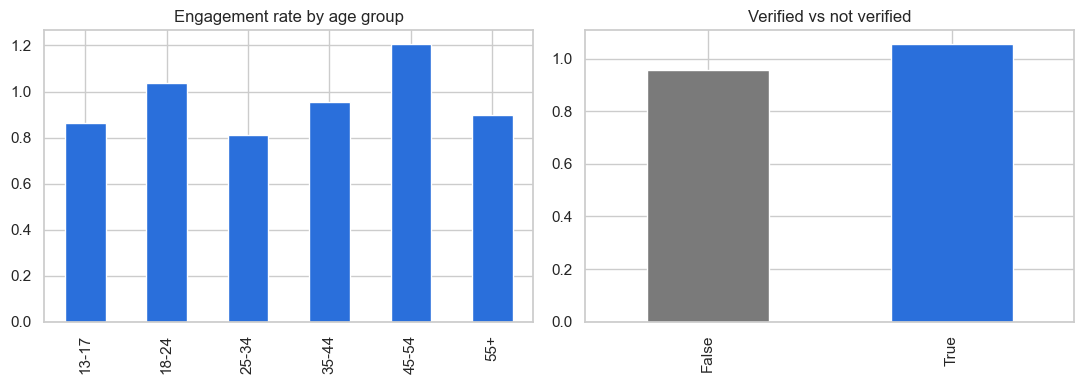

In [80]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
age_tbl.plot(kind="bar", ax=ax[0], color="#2a6fdb"); ax[0].set_title("Engagement rate by age group"); ax[0].set_xlabel("")
ver_tbl[er].plot(kind="bar", ax=ax[1], color=["#7a7a7a", "#2a6fdb"]); ax[1].set_title("Verified vs not verified"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

#### Behavioural insights

In [81]:
if COL["hour"]:
    hr = df.groupby(COL["hour"])[COL["impressions"]].mean()
    tod = df.groupby("time_of_day")[COL["impressions"]].mean()
    display(tod.to_frame("avg_impressions"))
    best_hour = int(hr.idxmax())
    print("Best hour of day for impressions:", best_hour, f"({hr.max():,.0f} avg impressions)")
    hr.plot(kind="line", marker="o", figsize=(9, 4), color="#2a6fdb", title="Average impressions by hour")
    plt.xlabel("Hour"); plt.show()
else:
    best_hour = None
    print("No hour/time column in the dataset - time-of-day analysis not possible.")

dev = df.groupby(COL["device"])[COL["watch_time"]].agg(["mean", "median", "count"])
display(dev.sort_values("mean", ascending=False))

No hour/time column in the dataset - time-of-day analysis not possible.


,mean,median,count
device_type,,,
Mobile,"4,087.67","4,111.00",1684
Tablet,"3,979.70","4,072.00",1658
Desktop,"3,974.69","3,922.00",1658


#### Sentiment analysis

In [82]:
sent = df.groupby(COL["sentiment"]).agg(posts=(er, "size"), avg_eng_rate=(er, "mean"),
                                        avg_likes=(COL["likes"], "mean"),
                                        avg_comments=(COL["comments"], "mean"),
                                        avg_shares=(COL["shares"], "mean"),
                                        avg_watch_time=(COL["watch_time"], "mean"),
                                        avg_followers=(COL["followers"], "mean"))
display(sent.sort_values("avg_eng_rate", ascending=False))
display(pd.crosstab(df[COL["sentiment"]], df[COL["post_type"]], normalize="index").round(3) * 100)
best_sent = sent["avg_eng_rate"].idxmax()
print("Best-performing sentiment:", best_sent)

,posts,avg_eng_rate,avg_likes,avg_comments,avg_shares,avg_watch_time,avg_followers
sentiment,,,,,,,
Negative,960,1.04,"10,207.88","1,516.07","1,007.29","4,054.50","397,425.71"
Neutral,1527,0.99,"9,923.01","1,528.37",996.54,"4,031.71","390,560.01"
Positive,2513,0.92,"10,179.74","1,480.62","1,005.06","3,988.56","394,163.04"


post_type,Image,Reel,Text,Video
sentiment,,,,
Negative,23.00,26.60,24.40,26.00
Neutral,25.30,25.40,26.00,23.20
Positive,25.40,25.50,24.40,24.70


Best-performing sentiment: Negative


### One Page Summary

In [83]:
def pct(a, b): return (a / b - 1) * 100

top_t, low_t = by_type.index[0], by_type.index[-1]
top_c = by_cat.index[0]
top_ctry, low_ctry = by_country.index[0], by_country.index[-1]
best_age = age_tbl.idxmax()
v_yes = ver_tbl.loc[True, er] if True in ver_tbl.index else np.nan
v_no = ver_tbl.loc[False, er] if False in ver_tbl.index else np.nan
best_dev = dev["mean"].idxmax(); worst_dev = dev["mean"].idxmin()
neg = sent.loc["Negative"] if "Negative" in sent.index else None
neu = sent.loc["Neutral"] if "Neutral" in sent.index else None
r_imp = df[COL["likes"]].corr(df[COL["impressions"]])

hour_line = (f"Impressions peak at **{best_hour}:00**; the strongest time block is **{tod.idxmax()}**."
             if best_hour is not None else "The dataset has no time-of-day field, so hourly timing could not be analysed.")
neg_line = (f"Negative posts average an engagement rate of **{neg['avg_eng_rate']:.2f}** vs "
            f"**{sent['avg_eng_rate'].mean():.2f}** overall; neutral posts average **{neu['avg_eng_rate']:.2f}**."
            if neg is not None and neu is not None else "")

summary = f"""
# Social Media Engagement Analytics - Summary

**Data.** {len(df):,} posts after cleaning (duplicates removed, missing values filled with median/mode,
negative and extreme values corrected, gender/sentiment labels standardised, hashtag count extracted).
Engagement metrics are right-skewed: a few viral posts pull the mean above the median
(likes mean {df[COL['likes']].mean():,.0f} vs median {df[COL['likes']].median():,.0f}), so medians are the safer typical value.
Likes and impressions are correlated at r = {r_imp:.2f}.

## Content performance
- **Post type:** **{top_t}** has the highest average engagement rate ({by_type[er].iloc[0]:.2f}); **{low_t}** is lowest ({by_type[er].iloc[-1]:.2f}).
- **Category:** **{top_c}** performs best ({by_cat[er].iloc[0]:.2f}).
- **Country:** **{top_ctry}** leads on average engagement rate ({by_country.iloc[0]:.2f}); **{low_ctry}** is lowest ({by_country.iloc[-1]:.2f}).

## User trends
- **Age:** engagement rate is highest for the **{best_age}** group; correlation of age with engagement rate is {df[COL['age']].corr(df[er]):.2f}.
- **Verified accounts:** engagement rate {v_yes:.2f} verified vs {v_no:.2f} not verified ({pct(v_yes, v_no):+.1f}%).

## Behavioural insights
- {hour_line}
- **Device:** **{best_dev}** users have the longest average watch time ({dev.loc[best_dev, 'mean']:.1f}); **{worst_dev}** the shortest ({dev.loc[worst_dev, 'mean']:.1f}).

## Sentiment
- **{best_sent}** posts perform best (avg engagement rate {sent.loc[best_sent, 'avg_eng_rate']:.2f}).
- {neg_line}

## Recommendations
1. Prioritise **{top_t}** content in the **{top_c}** category.
2. Post around the peak time shown above.
3. Target the **{best_age}** age group and the **{top_ctry}** market.
4. Optimise watch-time-heavy content for **{best_dev}** viewers.

*Caveat: differences between groups can be small relative to the spread within each group. Check the box/violin plots before acting on a gap.*
"""
display(Markdown(summary))
open("summary.md", "w", encoding="utf-8").write(summary)


# Social Media Engagement Analytics - Summary

**Data.** 5,000 posts after cleaning (duplicates removed, missing values filled with median/mode,
negative and extreme values corrected, gender/sentiment labels standardised, hashtag count extracted).
Engagement metrics are right-skewed: a few viral posts pull the mean above the median
(likes mean 10,107 vs median 10,106), so medians are the safer typical value.
Likes and impressions are correlated at r = 0.01.

## Content performance
- **Post type:** **Video** has the highest average engagement rate (1.12); **Reel** is lowest (0.78).
- **Category:** **Food** performs best (1.36).
- **Country:** **Brazil** leads on average engagement rate (1.54); **USA** is lowest (0.58).

## User trends
- **Age:** engagement rate is highest for the **45-54** group; correlation of age with engagement rate is 0.01.
- **Verified accounts:** engagement rate 1.05 verified vs 0.95 not verified (+10.4%).

## Behavioural insights
- The dataset has no time-of-day field, so hourly timing could not be analysed.
- **Device:** **Mobile** users have the longest average watch time (4087.7); **Desktop** the shortest (3974.7).

## Sentiment
- **Negative** posts perform best (avg engagement rate 1.04).
- Negative posts average an engagement rate of **1.04** vs **0.98** overall; neutral posts average **0.99**.

## Recommendations
1. Prioritise **Video** content in the **Food** category.
2. Post around the peak time shown above.
3. Target the **45-54** age group and the **Brazil** market.
4. Optimise watch-time-heavy content for **Mobile** viewers.

*Caveat: differences between groups can be small relative to the spread within each group. Check the box/violin plots before acting on a gap.*


1731